---

<table style="width:100%">
  <tr>
    <th>
        <div style="text-align: center; background-color: #f0f0f0; padding: 20px; border-radius: 10px;">
<p style="text-align: center;"> Конспект лекцій з предмету: </p>
<p style="text-align: center;"><b><h2>"Схемотехніка радіотехнічних пристроїв. Частина 1"</h2></b></p>
<p style="text-align: center;"><b><h3>Тема 2. Багатокаскадні підсилювачі. Зворотний зв'язок і стійкість</h3></b></p>
<p style="text-align: center;"> Національний університет "Чернігівська політехніка"</p>
<hr/>
<p style="text-align: center;"><b>Питання теми:</b></p>
<ul style="text-align: left;">
  <li>1.6. Параметри багатокаскадних підсилювачів</li>
  <li>1.7. Основне рівняння зворотного зв'язку. Позитивний і негативний зворотний зв'язок. Фактор зворотного зв'язку</li>
  <li>1.8. Типи зворотних зв'язків у підсилювачах</li>
  <li>1.9–1.10. Вплив негативного зворотного зв'язку на коефіцієнти підсилення за струмом і напругою, на вхідний і вихідний опори</li>
  <li>1.11. Вплив негативного зворотного зв'язку на АЧХ і ФЧХ підсилювача</li>
  <li>1.12. Стійкість двокаскадних підсилювачів (корекція «вперед», корекція «назад»)</li>
</ul>
</div>
    </th>
    <th>
<div style="text-align: center; background-color: #f0f0f0; padding: 20px; border-radius: 10px;">
<p style="text-align: center;"> <b>Викладач:</b> </p>
<p style="text-align: center;"> Доктор філософії</p>
<p style="text-align: center;"> Пахалюк Богдан Петрович</p>
<hr/>
<p style="text-align: center; font-size: 0.9em;">Тема 2 з 14</p>
</div>
    </th>
  </tr>
</table>

---


---

<p style="text-align: center;"><b>Зміст</b></p>

* [Параметри багатокаскадних підсилювачів](#multistage)
    * [🔬 Інтерактивно: звуження смуги в багатокаскадному підсилювачі](#multistage-interactive)
* [Основне рівняння зворотного зв'язку](#fb-equation)
    * [🔬 Інтерактивно: стабілізація коефіцієнта підсилення негативним ЗЗ](#fb-sens-interactive)
* [Типи зворотних зв'язків у підсилювачах](#fb-types)
* [Вплив НЗЗ на коефіцієнти підсилення, вхідний і вихідний опори](#fb-impedance)
    * [🔬 Інтерактивно: вплив глибини НЗЗ на АЧХ двокаскадного підсилювача (PySpice)](#fb-spice-interactive)
* [Вплив НЗЗ на АЧХ і ФЧХ підсилювача](#fb-frequency)
    * [🔬 Інтерактивно: АЧХ, ФЧХ і перехідна характеристика при різній глибині НЗЗ](#fb-bode-interactive)
* [Стійкість підсилювачів зі зворотним зв'язком. Двокаскадні підсилювачі, корекція «вперед» і «назад»](#stability)
    * [🔬 Інтерактивно: стійкість двокаскадного підсилювача та корекція «назад» / «вперед»](#compensation-interactive)
    * [🔬 Інтерактивно: годограф Найквіста трикаскадного підсилювача](#nyquist-interactive)
* [📌 Підсумок теми](#topic-summary)
* [📚 Рекомендована література та ресурси](#references)

> 💡 Код демонстрацій та інтерактивних графіків **згорнуто**, щоб не відволікати від матеріалу. Щоб переглянути його, натисніть на «⋯» (або на смужку ліворуч від комірки). Для роботи інтерактивних елементів виконайте всі комірки: *Run → Run All Cells*.

---

**Підключення бібліотек.** NumPy/SciPy/Matplotlib — чисельні розрахунки та графіки, SymPy — символьні обчислення, ipywidgets — інтерактивні повзунки, PySpice + ngspice — моделювання схем (ОП μA741, таймер 555 та транзистори описано SPICE-моделями з теки `spice/`), schemdraw — побудова схем з умовними позначеннями за ДСТУ. Цю комірку потрібно виконати першою; у Google Colab вона спершу встановлює ngspice і бібліотеки (близько хвилини).

In [1]:
import sys, os
if 'google.colab' in sys.modules and not os.path.exists('/usr/lib/x86_64-linux-gnu/libngspice.so'):   # Google Colab: ngspice та бібліотеки (~1 хв)
    !apt-get -qq install -y ngspice libngspice0-dev > /dev/null
    %pip install -q PySpice==1.5 schemdraw==0.23 engineering_notation==0.13.3

# SPICE-моделі компонентів (ОП μA741, таймер 555, діоди, транзистори) лежать у теці spice/;
# якщо зошит відкрито окремо (напр. у Colab), завантажуємо їх із репозиторію
SPICE_DIR = 'spice'
if not os.path.isdir(SPICE_DIR):
    import urllib.request
    os.makedirs(SPICE_DIR, exist_ok=True)
    _repo = 'https://raw.githubusercontent.com/vim4all/Lectures_Schematics_of_radio_technical-devices_in_Ukrainian/main/spice/'
    for _f in ['uA741.lib', 'BIP-555.lib', '1N4007.mod', '2n2222a.lib', '2n3904.lib']:
        urllib.request.urlretrieve(_repo + _f, os.path.join(SPICE_DIR, _f))
def spice_model(name):
    return os.path.abspath(os.path.join(SPICE_DIR, name))

import warnings
warnings.filterwarnings('ignore', message='Unable to import Axes3D')
import sympy as smp
from sympy import symbols, Matrix, simplify, factor, solve, Eq, latex
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal
from ipywidgets import interact, interactive, fixed, HBox, VBox, Output
import ipywidgets as widgets
from IPython.display import display, HTML, Markdown
%matplotlib inline
try:                                     # схеми й графіки — лише PNG (менший розмір зошитів)
    get_ipython().display_formatter.formatters['image/svg+xml'].enabled = False
except Exception:
    pass

import math
from engineering_notation import EngNumber

import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging(logging_level='ERROR')
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

# ngspice ≥ 41 пише в stderr інформаційні повідомлення (напр. "Using SPARSE 1.3 as Direct Linear Solver"),
# які PySpice 1.5 вважає помилкою симуляції. Сприймаємо як помилку лише рядки, що містять "error".
from PySpice.Spice.NgSpice import Shared as _ngspice_shared
_orig_send_char = _ngspice_shared.NgSpiceShared._send_char
def _send_char(message_c, ngspice_id, user_data):
    message = _ngspice_shared.ffi_string_utf8(message_c)
    prefix, _, content = message.partition(' ')
    if prefix == 'stderr' and 'error' not in content.lower() and 'init file' not in content:
        self = _ngspice_shared.ffi.from_handle(user_data)
        self._stderr.append(content)
        return self.send_char(message, ngspice_id)
    return _orig_send_char(message_c, ngspice_id, user_data)
_ngspice_shared.NgSpiceShared._send_char = staticmethod(_send_char)

def opamp_circuit(title, supply=15):
    """Схема з ОП μA741 і двополярним живленням ±supply (вузли vcc, vee)."""
    c = Circuit(title)
    c.include(spice_model('uA741.lib'))
    c.V('cc', 'vcc', c.gnd, supply)
    c.V('ee', 'vee', c.gnd, -supply)
    return c

def add_opamp(c, name, plus, minus, out):
    """ОП μA741: X<name> (+) (−) Vcc Vee вихід."""
    c.X(name, 'UA741', plus, minus, 'vcc', 'vee', out)

def tran(c, step, stop, start=0, **kw):
    """Перехідний аналіз: повертає (t, словник напруг вузлів у вигляді numpy-масивів)."""
    a = c.simulator(temperature=25, nominal_temperature=25).transient(step_time=step, end_time=stop, start_time=start, **kw)
    return np.array(a.time), {str(k): np.array(v) for k, v in a.nodes.items()}

def ac(c, f_start=1, f_stop=10e6, points=40):
    """AC-аналіз: повертає (f, словник комплексних напруг вузлів)."""
    a = c.simulator(temperature=25, nominal_temperature=25).ac(start_frequency=f_start, stop_frequency=f_stop,
                                                                 number_of_points=points, variation='dec')
    return np.array(a.frequency), {str(k): np.array(v) for k, v in a.nodes.items()}

def db(x):
    return 20 * np.log10(np.maximum(np.abs(x), 1e-12))

try:
    import schemdraw
    import schemdraw.elements as elm
    SCHEMDRAW_AVAILABLE = True
except ImportError:
    SCHEMDRAW_AVAILABLE = False
    print('schemdraw не встановлено (pip install schemdraw)')

plt.rcParams.update({
    'figure.figsize': (8, 4), 'axes.grid': True, 'grid.alpha': 0.3,
    'axes.labelsize': 12, 'axes.titlesize': 13, 'lines.linewidth': 2,
    'font.size': 11,
})

if SCHEMDRAW_AVAILABLE:
    # Умовні позначення за ДСТУ/IEC: резистор — прямокутник, джерело ЕРС — коло зі стрілкою,
    # операційний підсилювач — прямокутник із символом ▷∞, логічні елементи — прямокутники з «&», «1»
    from schemdraw.segments import Segment, SegmentCircle, SegmentText
    elm.style(elm.STYLE_IEC)
    schemdraw.use('matplotlib')
    import schemdraw.backends.svgtext as _svgtext       # оцінювач розміру тексту schemdraw не сприймає символ «&»
    _orig_text_size = _svgtext.text_approx_size
    _svgtext.text_approx_size = lambda text, *a, **k: _orig_text_size(text.replace('&', '8'), *a, **k)

    class EMF(elm.Source):
        """Джерело ЕРС: стрілка всередині кола вказує напрямок дії ЕРС."""
        def __init__(self, **kwargs):
            super().__init__(**kwargs)
            self.segments.append(Segment([(.2, 0), (.8, 0)], arrow='->', arrowwidth=.16, arrowlength=.25))

    class CurrentSource(elm.Source):
        """Джерело струму: подвійна стрілка вказує напрямок струму."""
        def __init__(self, **kwargs):
            super().__init__(**kwargs)
            self.segments.append(Segment([(.15, 0), (.85, 0)], arrow='->', arrowwidth=.16, arrowlength=.2))
            self.segments.append(Segment([(.15, 0), (.62, 0)], arrow='->', arrowwidth=.16, arrowlength=.2))

    class OpAmp(elm.Element):
        """Операційний підсилювач за ДСТУ: прямокутник із символом ▷∞.
        Інвертувальний вхід in1 (з кружечком інверсії) — угорі, неінвертувальний in2 — унизу;
        swap=True міняє входи місцями (неінвертувальний — угорі). Виводи: in1, in2, out, vd (живлення +), vs (живлення −)."""
        def __init__(self, swap=False, signs=True, **kwargs):
            super().__init__(**kwargs)
            w, h, lead, r = 2.0, 2.6, 0.6, 0.12
            yi, yn = (0.65, -0.65) if not swap else (-0.65, 0.65)
            self.segments.append(Segment([(0, h/2), (w, h/2), (w, -h/2), (0, -h/2), (0, h/2)]))
            self.segments.append(Segment([(0.55, h/2 - 0.3), (0.55, h/2 - 0.8), (0.95, h/2 - 0.55), (0.55, h/2 - 0.3)]))
            self.segments.append(SegmentText((1.35, h/2 - 0.55), '∞', fontsize=14))
            self.segments.append(SegmentCircle((-r, yi), r))
            self.segments.append(Segment([(-lead, yi), (-2*r, yi)]))
            self.segments.append(Segment([(-lead, yn), (0, yn)]))
            self.segments.append(Segment([(w, 0), (w + lead, 0)]))
            if signs:
                self.segments.append(SegmentText((0.25, yi), '−', fontsize=12))
                self.segments.append(SegmentText((0.25, yn), '+', fontsize=12))
            self.anchors.update({'in1': (-lead, yi), 'in2': (-lead, yn), 'out': (w + lead, 0),
                                 'vd': (w/2, h/2), 'vs': (w/2, -h/2), 'center': (w/2, 0)})
            self.elmparams['drop'] = (w + lead, 0)
            self.theta(0)            # не успадковувати напрямок попереднього елемента

    class Gate(elm.Element):
        """Логічний елемент за ДСТУ: прямокутник із функцією ('&', '1', '=1') і кружечком інверсії на виході.
        Виводи: in1 … inN (зверху вниз), out."""
        def __init__(self, func='&', inputs=2, inv=True, **kwargs):
            super().__init__(**kwargs)
            w, lead, r = 1.4, 0.5, 0.12
            h = max(1.4, 0.8 * inputs)
            self.segments.append(Segment([(0, h/2), (w, h/2), (w, -h/2), (0, -h/2), (0, h/2)]))
            self.segments.append(SegmentText((w/2, h/2 - 0.3), func, fontsize=13))
            ys = [0.0] if inputs == 1 else list(np.linspace(h/2 - 0.4, -h/2 + 0.4, inputs))
            for k, y in enumerate(ys):
                self.segments.append(Segment([(-lead, y), (0, y)]))
                self.anchors[f'in{k+1}'] = (-lead, y)
            x0 = w
            if inv:
                self.segments.append(SegmentCircle((w + r, 0), r))
                x0 = w + 2*r
            self.segments.append(Segment([(x0, 0), (w + lead, 0)]))
            self.anchors.update({'out': (w + lead, 0), 'center': (w/2, 0)})
            self.elmparams['drop'] = (w + lead, 0)
            self.theta(0)            # не успадковувати напрямок попереднього елемента

---

## Параметри багатокаскадних підсилювачів <a class="anchor" id="multistage"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 1.6</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Розраховувати загальний коефіцієнт підсилення, АЧХ і ФЧХ багатокаскадного підсилювача
> - Оцінювати шум і нелінійні спотворення багатокаскадного тракту та пояснювати роль першого і останнього каскадів
> - Визначати граничні частоти тракту з однакових каскадів

</div>

Одного каскаду часто недостатньо для отримання потрібного підсилення, тому каскади вмикають **послідовно**: вихід попереднього є джерелом сигналу для наступного, а вхідний опір наступного — навантаженням попереднього.

**Загальний коефіцієнт підсилення** дорівнює добутку коефіцієнтів каскадів (кожен — з урахуванням навантаження наступним каскадом):
$$K_{заг} = K_1 K_2\cdots K_N,\qquad K_{заг}[\text{дБ}] = \sum_{i=1}^{N} K_i[\text{дБ}].$$

**АЧХ і ФЧХ.** Логарифмічна АЧХ тракту — сума логарифмічних АЧХ каскадів; ФЧХ — сума фазових зсувів:
$$\varphi_{заг}(f) = \sum_{i=1}^N\varphi_i(f).$$
Звідси важливий наслідок: смуга тракту **вужча**, ніж смуга кожного каскаду. Для $N$ однакових каскадів першого порядку
$$f_{в.заг} = f_в\sqrt{2^{1/N}-1},\qquad f_{н.заг} = \frac{f_н}{\sqrt{2^{1/N}-1}}.$$
Наприклад, при $N=3$ множник $\sqrt{2^{1/3}-1} = 0{,}51$ — смуга звужується вдвічі з кожного боку.

**Шуми.** Шум кожного каскаду, приведений до входу тракту, ділиться на підсилення всіх попередніх каскадів:
$$U_{ш.вх}^2 = U_{ш1}^2 + \frac{U_{ш2}^2}{K_1^2} + \frac{U_{ш3}^2}{K_1^2K_2^2} + \dots,\qquad F_{заг} = F_1 + \frac{F_2-1}{K_{p1}} + \frac{F_3-1}{K_{p1}K_{p2}} + \dots$$
(друга формула — **формула Фріїса** для коефіцієнта шуму). При $K_1 \gg 1$ шуми тракту визначаються **першим каскадом**, тому його виконують малошумним.

**Нелінійні спотворення** виникають переважно в останніх каскадах, де сигнал найбільший. Якщо гармоніки каскадів некорельовані, загальний коефіцієнт гармонік оцінюють середньоквадратичною сумою $K_{г.заг} \approx \sqrt{\sum K_{гi}^2}$ (у гіршому випадку — арифметичною сумою).

**Динамічний діапазон** тракту не перевищує динамічного діапазону найгіршого каскаду: знизу його обмежує шум першого каскаду, зверху — перевантаження останнього.

**Міжкаскадні зв'язки:** ємнісний (розділювальні конденсатори — немає взаємного впливу режимів, але $f_н > 0$), трансформаторний (узгодження опорів, гальванічна розв'язка) і безпосередній (гальванічний — для ППС і мікросхем, $f_н = 0$, але режими каскадів взаємозалежні і з'являється дрейф).

---
### 🔬 Інтерактивно: звуження смуги в багатокаскадному підсилювачі <a class="anchor" id="multistage-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

$N$ однакових каскадів з коефіцієнтом $K_1$, нижньою частотою $f_н$ і верхньою $f_в$. Пунктир — АЧХ одного каскаду (зведена до того самого рівня). Зверніть увагу: зі зростанням $N$ підсилення росте пропорційно $N$ (у дБ), а смуга звужується.

</div>

In [2]:
# АЧХ N однакових каскадів першого порядку
def multistage(N=3, K1_dB=20.0, fn=100.0, fv_kHz=100.0):
    f = np.logspace(0, 7, 1500)
    fv = fv_kHz * 1e3
    K1 = 10 ** (K1_dB / 20) * (1j * f / fn) / (1 + 1j * f / fn) / (1 + 1j * f / fv)
    K = K1 ** N
    m = np.sqrt(2 ** (1 / N) - 1)
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True)
    a1.semilogx(f, db(K), color='#2196F3', label=f'{N} каскад(и)')
    a1.semilogx(f, db(K1) + (N - 1) * K1_dB, 'k--', lw=1, label='1 каскад (зсунуто)')
    a1.axhline(N * K1_dB - 3, color='#FF9800', ls=':', label='−3 дБ')
    a1.axvline(fv * m, color='#F44336', ls='--', lw=1); a1.axvline(fn / m, color='#F44336', ls='--', lw=1)
    a1.set_ylim(N * K1_dB - 40, N * K1_dB + 5); a1.set_ylabel('K, дБ'); a1.legend(loc='lower center')
    a1.set_title(f'K = {N*K1_dB:.0f} дБ;  смуга {fn/m:.0f} Гц … {fv*m/1e3:.1f} кГц')
    a2.semilogx(f, np.degrees(np.unwrap(np.angle(K))) - 360 * np.round(np.degrees(np.unwrap(np.angle(K)))[np.argmin(abs(f - np.sqrt(fn * fv)))] / 360), color='#FF9800')
    a2.set_ylabel('φ, град'); a2.set_xlabel('Частота, Гц')
    plt.tight_layout(); plt.show()
    print(f'Множник звуження √(2^(1/N) − 1) = {m:.3f}')

interact(multistage,
         N=widgets.IntSlider(min=1, max=6, value=3, description='N'),
         K1_dB=widgets.FloatSlider(min=6, max=40, step=1, value=20, description='K₁ (дБ)'),
         fn=widgets.FloatLogSlider(base=10, min=0, max=3, step=0.05, value=100, description='fн (Гц)'),
         fv_kHz=widgets.FloatLogSlider(base=10, min=0, max=3, step=0.05, value=100, description='fв (кГц)'));

interactive(children=(IntSlider(value=3, description='N', max=6, min=1), FloatSlider(value=20.0, description='…

---

## Основне рівняння зворотного зв'язку <a class="anchor" id="fb-equation"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 1.7</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Вивести основне рівняння зворотного зв'язку
> - Розрізняти позитивний і негативний зворотний зв'язок, пояснювати зміст петльового підсилення і фактора зворотного зв'язку
> - Пояснювати, чому глибокий НЗЗ робить коефіцієнт підсилення незалежним від параметрів активних елементів

</div>

**Зворотний зв'язок (ЗЗ)** — передавання частини вихідного сигналу підсилювача на його вхід. ЗЗ — основний засіб покращення параметрів підсилювачів: поліпшення одних параметрів (стабільності, лінійності, смуги) досягається ціною погіршення інших, менш важливих у даному випадку (насамперед — зменшення коефіцієнта підсилення).

Структура підсилювача з ЗЗ: основний підсилювач з коефіцієнтом $K$, ланка ЗЗ з коефіцієнтом передачі $\beta$ і пристрій порівняння (суматор) на вході.

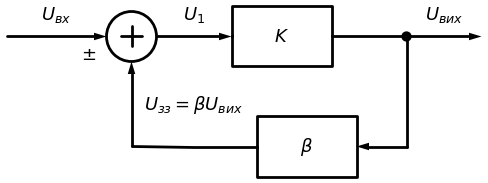

In [3]:
# Структурна схема підсилювача із зворотним зв'язком
if SCHEMDRAW_AVAILABLE:
    import schemdraw.dsp as dsp
    with schemdraw.Drawing(fontsize=13, unit=1.5) as d:
        d += dsp.Arrow().at((0, 0)).right(2).label('$U_{вх}$', loc='top')
        d += (s := dsp.Sum().anchor('W'))
        d += dsp.Arrow().at(s.E).right(1.5).label('$U_1$', loc='top')
        d += (k := dsp.Box(w=2, h=1.2).label('$K$').anchor('W'))
        d += dsp.Line().at(k.E).right(1.5)
        d += (n := elm.Dot())
        d += dsp.Arrow().right(1.5).label('$U_{вих}$', loc='top')
        d += dsp.Line().at(n.center).down(2.2)
        d += dsp.Arrow().left(1.0)
        d += (b := dsp.Box(w=2, h=1.2).label('$\\beta$').anchor('E'))
        d += dsp.Line().at(b.W).left().tox(s.S)
        d += dsp.Arrow().up().toy(s.S).label('$U_{зз} = \\beta U_{вих}$', loc='bottom')
        d += elm.Label().at((s.center[0] - 0.75, s.center[1] - 0.45)).label('±')

### Виведення

Позначимо: $U_{вх}$ — вхідний сигнал, $U_{зз} = \beta U_{вих}$ — сигнал зворотного зв'язку, $U_1$ — сигнал на вході основного підсилювача, $U_{вих} = K U_1$.

Для **загального випадку** (знак ЗЗ визначається фазами $K$ і $\beta$) на суматорі $U_1 = U_{вх} + \beta U_{вих}$:
$$U_{вих} = K\,(U_{вх} + \beta U_{вих})\;\Rightarrow\; \boxed{K_{зз} = \frac{U_{вих}}{U_{вх}} = \frac{K}{1-\beta K}}$$
— **основне рівняння зворотного зв'язку**.

- $\beta K$ — **петльове підсилення** (підсилення сигналу при обході замкненої петлі);
- $F = 1 - \beta K$ — **фактор (глибина) зворотного зв'язку**: показує, у скільки разів змінюється коефіцієнт підсилення після введення ЗЗ: $K_{зз} = K/F$.

**Негативний ЗЗ (НЗЗ):** сигнал ЗЗ надходить у протифазі до вхідного і віднімається від нього: $\beta K < 0$, $|F| > 1$, $K_{зз} < K$. Зручно записувати, вважаючи $\beta K > 0$, а віднімання — в суматорі ($U_1 = U_{вх} - \beta U_{вих}$):
$$K_{зз} = \frac{K}{1+\beta K},\qquad F = 1 + \beta K.$$
Протифазність найчастіше забезпечують інвертувальним основним підсилювачем і неінвертувальною ланкою $\beta$ (або подають сигнал ЗЗ на інший вхід — як в ОП).

**Позитивний ЗЗ (ПЗЗ):** сигнал ЗЗ додається до вхідного у фазі: $0 < \beta K < 1$, $0 < F < 1$, $K_{зз} > K$. При $\beta K \to 1$: $F \to 0$, $K_{зз} \to \infty$ — підсилювач **самозбуджується** (перетворюється на генератор, теми 12–13) або переходить у тригерний режим (тригер Шмітта, тема 9).

**Глибокий НЗЗ** ($\beta K \gg 1$):
$$K_{зз} = \frac{K}{1+\beta K} \approx \frac{1}{\beta}$$
— коефіцієнт підсилення визначається **лише ланкою ЗЗ** (зазвичай — відношенням стабільних резисторів) і майже не залежить від параметрів транзисторів, температури і напруги живлення. На цьому принципі побудовано всі схеми на операційних підсилювачах.

**Стабільність коефіцієнта підсилення.** Продиференціювавши основне рівняння, отримаємо
$$\frac{dK_{зз}}{K_{зз}} = \frac{1}{1+\beta K}\cdot\frac{dK}{K} = \frac{1}{F}\cdot\frac{dK}{K}:$$
відносна нестабільність коефіцієнта підсилення зменшується у $F$ разів.

У реальних підсилювачах $K$ і $\beta$ залежать від частоти, тому НЗЗ на одних частотах може стати ПЗЗ на інших (додатковий фазовий зсув у петлі досягає $180°$). Це головна причина самозбудження підсилювачів зі ЗЗ (див. розділ про стійкість).

---
### 🔬 Інтерактивно: стабілізація коефіцієнта підсилення негативним ЗЗ <a class="anchor" id="fb-sens-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Коефіцієнт $K$ основного підсилювача змінюється в широких межах (розкид параметрів транзисторів, температура). Задайте $\beta$ і подивіться, як мало при цьому змінюється $K_{зз}$. Червоні маркери — номінальне значення $K_{ном}$ та відхилення на ±50 %.

</div>

In [4]:
# K_зз = K/(1+βK): нечутливість до K при глибокому НЗЗ
def fb_sens(beta=0.01, K_nom=1000.0):
    K = np.logspace(0, 6, 400)
    Kf = K / (1 + beta * K)
    fig, ax = plt.subplots(figsize=(8.5, 4))
    ax.loglog(K, Kf, color='#2196F3', label='$K_{зз}$')
    ax.loglog(K, K, 'k--', lw=1, label='без ЗЗ')
    ax.axhline(1 / beta, color='#4CAF50', ls=':', label='$1/\\beta$')
    pts = np.array([0.5, 1, 1.5]) * K_nom
    ax.plot(pts, pts / (1 + beta * pts), 'o', color='#F44336')
    ax.set_xlabel('K (без ЗЗ)'); ax.set_ylabel('$K_{зз}$'); ax.legend(); ax.set_ylim(0.5, 2e6)
    ax.set_title(f'β = {beta:g}:  F = 1 + βK = {1 + beta*K_nom:.1f}')
    plt.tight_layout(); plt.show()
    k = pts / (1 + beta * pts)
    print(f'K змінюється від {pts[0]:.0f} до {pts[2]:.0f} (±50 %);  K_зз — від {k[0]:.2f} до {k[2]:.2f} '
          f'({(k[2]-k[0])/2/k[1]*100:+.1f} %)')

interact(fb_sens,
         beta=widgets.FloatLogSlider(base=10, min=-4, max=0, step=0.1, value=0.01, description='β'),
         K_nom=widgets.FloatLogSlider(base=10, min=1, max=5, step=0.1, value=1000, description='K ном'));

interactive(children=(FloatLogSlider(value=0.01, description='β', max=0.0, min=-4.0), FloatLogSlider(value=100…

---

## Типи зворотних зв'язків у підсилювачах <a class="anchor" id="fb-types"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 1.8</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Класифікувати ЗЗ за способом зняття сигналу з виходу і способом введення на вхід
> - Розпізнавати тип ЗЗ на принциповій схемі за допомогою «тесту короткого замикання»

</div>

Основний підсилювач і ланка ЗЗ — чотириполюсники, тому їх можна з'єднати чотирма способами.

**За способом зняття сигналу з виходу:**
- **ЗЗ за напругою** — вхід ланки $\beta$ ввімкнено **паралельно** навантаженню; сигнал ЗЗ пропорційний $U_{вих}$. *Тест:* якщо закоротити навантаження ($U_{вих}=0$), ЗЗ зникає.
- **ЗЗ за струмом** — вхід ланки $\beta$ ввімкнено **послідовно** з навантаженням; сигнал ЗЗ пропорційний $I_{вих}$. *Тест:* якщо розімкнути навантаження ($I_{вих}=0$), ЗЗ зникає.

**За способом введення на вхід:**
- **послідовний ЗЗ** — вихід ланки $\beta$ ввімкнено послідовно з джерелом сигналу; на вході **підсумовуються напруги**. *Тест:* якщо закоротити вхід, сигнал ЗЗ продовжує діяти на вхід підсилювача.
- **паралельний ЗЗ** — вихід ланки $\beta$ ввімкнено паралельно джерелу сигналу; на вході **підсумовуються струми**. *Тест:* якщо закоротити вхід, сигнал ЗЗ зникає.

Чотири комбінації та відповідні системи параметрів чотириполюсників:

| Тип ЗЗ | Вхід | Вихід | Параметри | Що стабілізується | Приклад |
|---|---|---|---|---|---|
| **послідовний за напругою** (H-тип) | послідовно | паралельно | $h$ | $K_u = U_{вих}/U_{вх}$ | неінвертувальний підсилювач на ОП, емітерний повторювач |
| **послідовний за струмом** (Z-тип) | послідовно | послідовно | $z$ | крутизна $I_{вих}/U_{вх}$ | каскад СЕ з резистором $R_е$ без шунтування |
| **паралельний за напругою** (Y-тип) | паралельно | паралельно | $y$ | трансопір $U_{вих}/I_{вх}$ | інвертувальний підсилювач, перетворювач струм→напруга |
| **паралельний за струмом** (G-тип; у деяких посібниках — K-тип) | паралельно | послідовно | $g$ | $K_i = I_{вих}/I_{вх}$ | підсилювач струму |

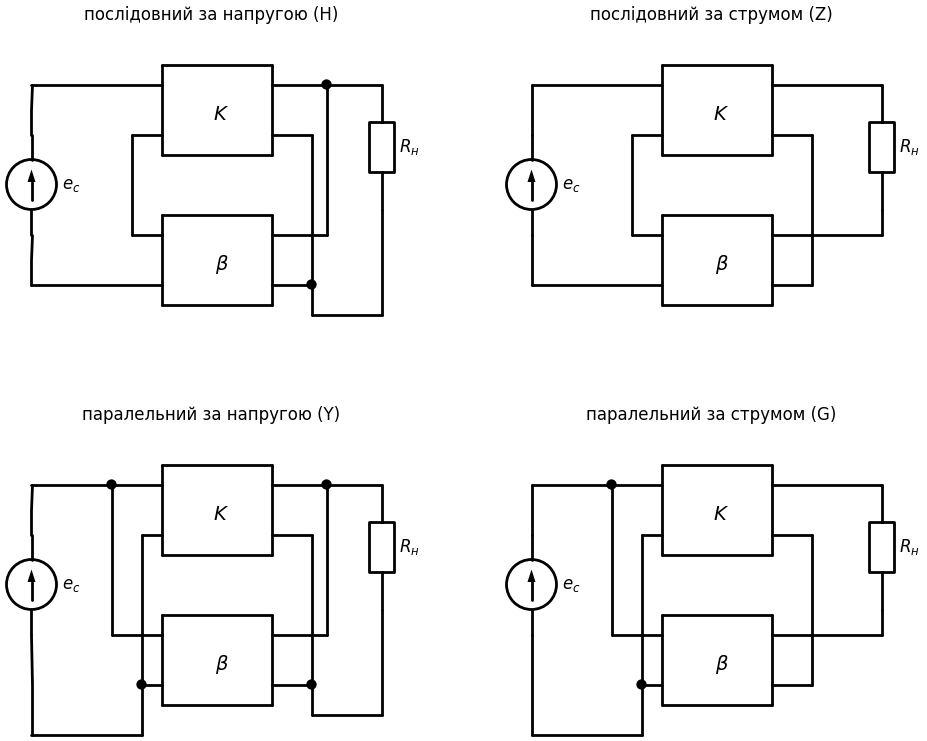

In [5]:
# Чотири типи зворотного зв'язку: K — основний підсилювач, β — ланка ЗЗ
if SCHEMDRAW_AVAILABLE:
    def block(d, x0, y0, w, h, text):
        for p1, p2 in [((x0, y0), (x0 + w, y0)), ((x0 + w, y0), (x0 + w, y0 + h)), ((x0 + w, y0 + h), (x0, y0 + h)), ((x0, y0 + h), (x0, y0))]:
            d += elm.Line().at(p1).to(p2)
        d += elm.Label().at((x0 + w / 2, y0 + h / 2)).label(text, fontsize=14)

    def fb_type(d, ox, oy, series_in, voltage_out, title):
        L = lambda a, b: elm.Line().at((ox + a[0], oy + a[1])).to((ox + b[0], oy + b[1]))
        block(d, ox + 2.6, oy + 2.6, 2.2, 1.8, '$K$')         # входи (2.6; 4.0) і (2.6; 3.0); виходи (4.8; 4.0) і (4.8; 3.0)
        block(d, ox + 2.6, oy - 0.4, 2.2, 1.8, '$\\beta$')    # «вхід» β праворуч (4.8; 1.0)/(4.8; 0.0), «вихід» ліворуч
        d += EMF().at((ox, oy + 1.0)).to((ox, oy + 3.0)).label('$e_c$', loc='bottom')
        d += elm.Label().at((ox + 3.7, oy + 5.3)).label(title, fontsize=12)
        if series_in:      # джерело, вхід K і вихід β — в одному контурі
            d += L((0, 3.0), (0, 4.0)); d += L((0, 4.0), (2.6, 4.0))
            d += L((2.6, 3.0), (2.0, 3.0)); d += L((2.0, 3.0), (2.0, 1.0)); d += L((2.0, 1.0), (2.6, 1.0))
            d += L((2.6, 0.0), (0, 0.0)); d += L((0, 0.0), (0, 1.0))
        else:              # джерело, вхід K і вихід β — паралельно між двома шинами
            d += L((0, 3.0), (0, 4.0)); d += L((0, 4.0), (2.6, 4.0)); d += L((1.6, 4.0), (1.6, 1.0)); d += L((1.6, 1.0), (2.6, 1.0))
            d += elm.Dot().at((ox + 1.6, oy + 4.0))
            d += L((0, 1.0), (0, -1.0)); d += L((0, -1.0), (2.2, -1.0)); d += L((2.2, -1.0), (2.2, 0.0)); d += L((2.2, 0.0), (2.6, 0.0))
            d += L((2.2, -1.0), (2.2, -1.0)); d += L((2.2, 0.0), (2.2, 3.0)); d += L((2.2, 3.0), (2.6, 3.0))
            d += elm.Dot().at((ox + 2.2, oy + 0.0))
        if voltage_out:    # вхід β паралельно навантаженню
            d += L((4.8, 4.0), (7.0, 4.0)); d += L((4.8, 3.0), (5.6, 3.0)); d += L((5.6, 3.0), (5.6, 0.0)); d += L((5.6, 0.0), (4.8, 0.0))
            d += L((5.9, 4.0), (5.9, 1.0)); d += L((5.9, 1.0), (4.8, 1.0)); d += elm.Dot().at((ox + 5.9, oy + 4.0))
            d += elm.Resistor().at((ox + 7.0, oy + 4.0)).to((ox + 7.0, oy + 1.5)).label('$R_н$', loc='bottom')
            d += L((7.0, 1.5), (7.0, -0.6)); d += L((7.0, -0.6), (5.6, -0.6)); d += L((5.6, -0.6), (5.6, 0.0))
            d += elm.Dot().at((ox + 5.6, oy + 0.0))
        else:              # вхід β послідовно з навантаженням
            d += L((4.8, 4.0), (7.0, 4.0))
            d += elm.Resistor().at((ox + 7.0, oy + 4.0)).to((ox + 7.0, oy + 1.5)).label('$R_н$', loc='bottom')
            d += L((7.0, 1.5), (7.0, 1.0)); d += L((7.0, 1.0), (4.8, 1.0))
            d += L((4.8, 0.0), (5.6, 0.0)); d += L((5.6, 0.0), (5.6, 3.0)); d += L((5.6, 3.0), (4.8, 3.0))

    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        fb_type(d, 0, 0, True, True, 'послідовний за напругою (H)')
        fb_type(d, 10, 0, True, False, 'послідовний за струмом (Z)')
        fb_type(d, 0, -8, False, True, 'паралельний за напругою (Y)')
        fb_type(d, 10, -8, False, False, 'паралельний за струмом (G)')

---

## Вплив НЗЗ на коефіцієнти підсилення, вхідний і вихідний опори <a class="anchor" id="fb-impedance"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 1.9, 1.10</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Визначати, як кожен тип НЗЗ змінює $K_u$, $K_i$, $R_{вх}$ і $R_{вих}$
> - Розраховувати вхідний і вихідний опори підсилювача з НЗЗ через фактор ЗЗ
> - Перевіряти розрахунок моделюванням двокаскадного підсилювача з загальним НЗЗ

</div>

Вплив НЗЗ на параметри підсилювача визначається **типом** ЗЗ. Загальне правило: НЗЗ стабілізує ту величину, з якої знімається сигнал ЗЗ, і зменшує у $F$ разів коефіцієнт передачі, що зв'язує величини, які підсумовуються на вході, з величиною, яка контролюється на виході.

**Вхідний опір** визначається способом введення:
- **послідовний НЗЗ збільшує** вхідний опір: на вході діє різниця напруг $U_{вх} - U_{зз}$, вхідний струм зменшується у $F$ разів:
$$R_{вх.зз} = R_{вх}\,(1 + \beta K) = R_{вх}F;$$
- **паралельний НЗЗ зменшує** вхідний опір: частина вхідного струму відгалужується в коло ЗЗ:
$$R_{вх.зз} = \frac{R_{вх}}{1 + \beta K} = \frac{R_{вх}}{F}.$$

**Вихідний опір** визначається способом зняття:
- **НЗЗ за напругою зменшує** вихідний опір (прагне підтримати незмінною $U_{вих}$ при зміні навантаження — підсилювач наближається до ідеального джерела напруги):
$$R_{вих.зз} = \frac{R_{вих}}{1 + \beta K_{хх}};$$
- **НЗЗ за струмом збільшує** вихідний опір (прагне підтримати $I_{вих}$ — наближення до джерела струму):
$$R_{вих.зз} = R_{вих}\,(1 + \beta K_{кз}).$$
Тут $K_{хх}$ і $K_{кз}$ — петльові коефіцієнти в режимах холостого ходу і короткого замикання виходу відповідно.

**Коефіцієнти підсилення:**
- **послідовний НЗЗ** зменшує $K_u$ у $F$ разів і практично не змінює $K_i$ (вхідний струм зменшується разом із вихідним);
- **паралельний НЗЗ** зменшує $K_i$ у $F$ разів і практично не змінює $K_u$ від вхідних затискачів підсилювача (але зменшує наскрізний коефіцієнт від ЕРС джерела з великим $R_c$).

| Тип НЗЗ | $R_{вх}$ | $R_{вих}$ | Зменшується в $F$ разів |
|---|---|---|---|
| послідовний за напругою | $\times F$ ↑ | $\div F$ ↓ | $K_u$ |
| послідовний за струмом | $\times F$ ↑ | $\times F$ ↑ | крутизна $S = I_{вих}/U_{вх}$ |
| паралельний за напругою | $\div F$ ↓ | $\div F$ ↓ | трансопір $R_т = U_{вих}/I_{вх}$ |
| паралельний за струмом | $\div F$ ↓ | $\times F$ ↑ | $K_i$ |

**Важливо для максимальної ефективності:** послідовний ЗЗ ефективний при малому опорі джерела сигналу ($R_c \to 0$, джерело напруги), паралельний — при великому ($R_c \to \infty$, джерело струму). ЗЗ за напругою найглибший при $R_н \to \infty$, за струмом — при $R_н \to 0$.

### Моделювання: двокаскадний підсилювач СЕ–СЕ з загальним послідовним НЗЗ за напругою

Два каскади зі спільним емітером на транзисторах 2N3904 ($E_ж = 12$ В). Кожен каскад інвертує, тож вихід другого каскаду синфазний із входом. Через коло $R_{зз}C_{зз}$ частина вихідної напруги подається в емітер першого транзистора, на резистор $R_{е1} = 100$ Ом, — це **послідовний** (напруга ЗЗ віднімається від напруги база–емітер) НЗЗ **за напругою** (знімається з навантаження паралельно). Очікуване підсилення з ЗЗ: $K_{зз} \approx 1/\beta = 1 + R_{зз}/R_{е1}$.

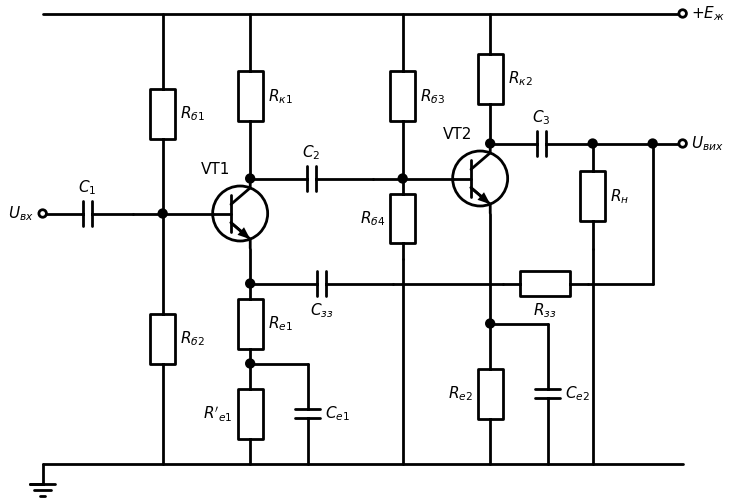

In [6]:
# Принципова схема двокаскадного підсилювача з загальним НЗЗ (коло R_зз C_зз — уздовж нижнього «коридору»)
if SCHEMDRAW_AVAILABLE:
    with schemdraw.Drawing(fontsize=11, unit=2) as d:
        W = lambda p1, p2: elm.Line().at(p1).to(p2)
        d += W((0, 9), (12.8, 9)); d += elm.Dot(open=True).at((12.8, 9)).label('$+E_ж$', loc='right')
        d += W((0, 0), (12.8, 0)); d += elm.Ground().at((0, 0))
        # каскад 1
        d += elm.Dot(open=True).at((0, 5)).label('$U_{вх}$', loc='left')
        d += elm.Capacitor().at((0, 5)).to((1.8, 5)).label('$C_1$')
        d += W((1.8, 5), (3.4, 5)); d += elm.Dot().at((2.4, 5))
        d += elm.Resistor().at((2.4, 9)).to((2.4, 5)).label('$R_{б1}$', loc='bottom')
        d += elm.Resistor().at((2.4, 5)).to((2.4, 0)).label('$R_{б2}$', loc='bottom')
        d += elm.BjtNpn(circle=True).theta(0).at((3.4, 5)).anchor('base'); d += elm.Label().at((3.35, 6.0)).label('VT1')
        d += elm.Resistor().at((4.15, 9)).to((4.15, 5.7)).label('$R_{к1}$', loc='bottom')
        d += W((4.15, 4.3), (4.15, 3.6)); d += elm.Dot().at((4.15, 3.6))
        d += elm.Resistor().at((4.15, 3.6)).to((4.15, 2.0)).label('$R_{е1}$', loc='bottom')
        d += elm.Dot().at((4.15, 2.0))
        d += elm.Resistor().at((4.15, 2.0)).to((4.15, 0)).label("$R'_{е1}$", loc='top')
        d += W((4.15, 2.0), (5.3, 2.0)); d += elm.Capacitor().at((5.3, 2.0)).to((5.3, 0)).label('$C_{е1}$', loc='bottom')
        # каскад 2
        d += elm.Dot().at((4.15, 5.7))
        d += elm.Capacitor().at((4.15, 5.7)).to((6.6, 5.7)).label('$C_2$')
        d += W((6.6, 5.7), (8.2, 5.7)); d += elm.Dot().at((7.2, 5.7))
        d += elm.Resistor().at((7.2, 9)).to((7.2, 5.7)).label('$R_{б3}$', loc='bottom')
        d += elm.Resistor().at((7.2, 5.7)).to((7.2, 4.1)).label('$R_{б4}$', loc='top'); d += W((7.2, 4.1), (7.2, 0))
        d += elm.BjtNpn(circle=True).theta(0).at((8.2, 5.7)).anchor('base'); d += elm.Label().at((8.2, 6.7)).label('VT2')
        d += elm.Resistor().at((8.95, 9)).to((8.95, 6.4)).label('$R_{к2}$', loc='bottom')
        d += W((8.95, 5.0), (8.95, 2.8)); d += elm.Dot().at((8.95, 2.8))
        d += elm.Resistor().at((8.95, 2.8)).to((8.95, 0)).label('$R_{е2}$', loc='top')
        d += W((8.95, 2.8), (10.1, 2.8)); d += elm.Capacitor().at((10.1, 2.8)).to((10.1, 0)).label('$C_{е2}$', loc='bottom')
        # вихід і навантаження
        d += elm.Dot().at((8.95, 6.4))
        d += elm.Capacitor().at((8.95, 6.4)).to((11.0, 6.4)).label('$C_3$')
        d += W((11.0, 6.4), (12.8, 6.4)); d += elm.Dot(open=True).at((12.8, 6.4)).label('$U_{вих}$', loc='right')
        d += elm.Dot().at((11.0, 6.4)); d += elm.Resistor().at((11.0, 6.4)).to((11.0, 4.3)).label('$R_н$', loc='bottom')
        d += W((11.0, 4.3), (11.0, 0))
        # коло зворотного зв'язку
        d += elm.Dot().at((12.2, 6.4)); d += W((12.2, 6.4), (12.2, 3.6)); d += W((12.2, 3.6), (10.9, 3.6))
        d += elm.Resistor().at((10.9, 3.6)).to((9.2, 3.6)).label('$R_{зз}$', loc='bottom')
        d += W((9.2, 3.6), (7.0, 3.6))
        d += elm.Capacitor().at((7.0, 3.6)).to((4.15, 3.6)).label('$C_{зз}$', loc='bottom')

---
### 🔬 Інтерактивно: вплив глибини НЗЗ на АЧХ двокаскадного підсилювача (PySpice) <a class="anchor" id="fb-spice-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Змінюйте опір $R_{зз}$ (0 — ЗЗ вимкнено). Порівнюйте коефіцієнт підсилення і смугу: добуток «підсилення × смуга» залишається приблизно сталим, а нижня гранична частота зменшується. Невеликий підйом АЧХ з НЗЗ на краях смуги — не похибка моделювання: розділювальні та блокувальні конденсатори і ємності транзисторів утворюють у петлі кілька полюсів, і запас стійкості на цих частотах зменшується (див. розділ про стійкість). Під графіком — розрахунок $K_{зз} \approx 1 + R_{зз}/R_{е1}$ та фактора $F = K/K_{зз}$.

</div>

In [7]:
# Двокаскадний підсилювач СЕ–СЕ на 2N3904 з загальним послідовним НЗЗ за напругою (AC-аналіз у PySpice)
def ce_ce(Rf_k=2.2, C_load_nF=1.0):
    def build(with_fb):
        c = Circuit('CE-CE with feedback')
        c.include(spice_model('2n3904.lib'))
        c.V('cc', 'vcc', c.gnd, 12)
        c.SinusoidalVoltageSource('in', 'src', c.gnd, amplitude=1e-3, ac_magnitude=1)
        c.C(1, 'src', 'b1', 10e-6); c.R('b1', 'vcc', 'b1', 82e3); c.R('b2', 'b1', c.gnd, 15e3)
        c.BJT(1, 'c1', 'b1', 'e1', model='Q2N3904')
        c.R('c1', 'vcc', 'c1', 4.7e3); c.R('e1', 'e1', 'e1b', 100); c.R('e1b', 'e1b', c.gnd, 1e3); c.C('e1', 'e1b', c.gnd, 100e-6)
        c.C(2, 'c1', 'b2', 10e-6); c.R('b3', 'vcc', 'b2', 82e3); c.R('b4', 'b2', c.gnd, 15e3)
        c.BJT(2, 'c2', 'b2', 'e2', model='Q2N3904')
        c.R('c2', 'vcc', 'c2', 4.7e3); c.R('e2', 'e2', c.gnd, 1e3); c.C('e2', 'e2', c.gnd, 100e-6)
        c.C(3, 'c2', 'out', 10e-6); c.R('L', 'out', c.gnd, 10e3); c.C('L', 'out', c.gnd, C_load_nF * 1e-9)
        if with_fb:
            c.R('f', 'out', 'fb', Rf_k * 1e3); c.C('f', 'fb', 'e1', 10e-6)
        return c
    res = {}
    for fb in (False, True):
        if fb and Rf_k <= 0:
            continue
        f, v = ac(build(fb), 0.1, 1e8, 30)
        res[fb] = (f, np.abs(v['out']))
    fig, ax = plt.subplots(figsize=(9, 4.2))
    info = []
    for fb, (f, g) in res.items():
        g0 = g.max(); band = f[g >= g0 / np.sqrt(2)]
        lab = f'з НЗЗ, Rзз = {Rf_k:.1f} кОм' if fb else 'без ЗЗ'
        ax.semilogx(f, db(g), color='#F44336' if fb else '#2196F3', label=lab)
        ax.plot([band[0], band[-1]], [db(g0) - 3] * 2, 'o', color='k', ms=4)
        info.append((lab, g0, band[0], band[-1]))
    ax.set_xlabel('Частота, Гц'); ax.set_ylabel('K, дБ'); ax.set_ylim(-10, 75); ax.legend()
    ax.set_title('АЧХ двокаскадного підсилювача СЕ–СЕ')
    plt.tight_layout(); plt.show()
    for lab, g0, fl, fh in info:
        print(f'{lab:24s}: K = {g0:7.1f} ({db(g0):.1f} дБ),  fн = {fl:8.2f} Гц,  fв = {fh/1e3:9.1f} кГц,  K·fв = {g0*fh/1e6:.0f} МГц')
    if len(info) == 2:
        print(f'Фактор ЗЗ F = {info[0][1]/info[1][1]:.1f};  оцінка 1/β = 1 + Rзз/Rе1 = {1 + Rf_k*1e3/100:.1f}')

interact(ce_ce,
         Rf_k=widgets.FloatSlider(min=0, max=20, step=0.2, value=2.2, description='Rзз (кОм)'),
         C_load_nF=widgets.FloatSlider(min=0.1, max=10, step=0.1, value=1, description='Cн (нФ)'));

interactive(children=(FloatSlider(value=2.2, description='Rзз (кОм)', max=20.0, step=0.2), FloatSlider(value=1…

### ⚠️ Типова помилка

<div style="background-color: #fef2f2; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #dc2626; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

**НЗЗ зменшує вхідний опір лише тоді, коли він паралельний.** Поширена помилка — вважати, що «зворотний зв'язок завжди зменшує опори». Вхідний опір залежить лише від способу *введення* сигналу ЗЗ (послідовний ↑, паралельний ↓), а вихідний — лише від способу *зняття* (за напругою ↓, за струмом ↑). Неінвертувальний підсилювач на ОП (послідовний за напругою) має дуже великий $R_{вх}$ і дуже малий $R_{вих}$, а інвертувальний (паралельний за напругою) — малий $R_{вх} \approx R_1$.

</div>

---

## Вплив НЗЗ на АЧХ і ФЧХ підсилювача <a class="anchor" id="fb-frequency"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 1.11</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Пояснити розширення смуги пропускання під дією НЗЗ
> - Застосовувати правило сталого добутку «підсилення × смуга»
> - Оцінювати вплив НЗЗ на нелінійні спотворення, шуми і перехідну характеристику

</div>

Оскільки НЗЗ зменшує відносні зміни коефіцієнта підсилення у $F$ разів, а спад АЧХ на краях смуги — це теж зміна $K$, то **АЧХ вирівнюється**, а смуга розширюється.

Для підсилювача з однополюсною ВЧ-характеристикою $K(j\omega) = \dfrac{K_0}{1 + j\omega/\omega_в}$:
$$K_{зз}(j\omega) = \frac{K(j\omega)}{1 + \beta K(j\omega)} = \frac{K_0/F}{1 + j\omega/(\omega_в F)},\qquad F = 1 + \beta K_0 .$$
Отже, коефіцієнт підсилення зменшується в $F$ разів, а верхня гранична частота **зростає в $F$ разів**:
$$f_{в.зз} = f_в F,\qquad K_{0.зз}\,f_{в.зз} = K_0 f_в = \text{const}.$$
Аналогічно нижня гранична частота **зменшується** в $F$ разів: $f_{н.зз} = f_н/F$.

Добуток $K_0 f_в$ називають **площею підсилення**; для операційних підсилювачів — це частота одиничного підсилення $f_1$ (наприклад, 1 МГц для μA741).

**Вплив на ФЧХ.** У смузі пропускання фазові зсуви також зменшуються (ФЧХ «вирівнюється»). Проте поблизу і за межами граничних частот фазовий зсув у петлі може досягти $180°$ — тоді НЗЗ перетворюється на ПЗЗ: з'являється підйом АЧХ, а при $|\beta K| \ge 1$ — самозбудження.

**Інші наслідки НЗЗ:**
- **нелінійні спотворення** зменшуються приблизно у $F$ разів: $K_{г.зз} \approx K_г/F$ (доки підсилювач не входить у насичення — глибоке обмеження ЗЗ не виправляє); найефективніший — загальний ЗЗ, що охоплює кілька каскадів;
- **динамічний діапазон** розширюється, амплітудна характеристика стає лінійнішою;
- **шум**, що виник *усередині* петлі (наприклад, у вихідному каскаді), зменшується у $F$ разів; але шум першого каскаду, приведений до входу, НЗЗ **не зменшує** — він підсилюється так само, як сигнал;
- **перехідна характеристика**: фронт коротшає (бо $f_в$ зростає), а при малому запасі стійкості з'являється викид і коливання.

---
### 🔬 Інтерактивно: АЧХ, ФЧХ і перехідна характеристика при різній глибині НЗЗ <a class="anchor" id="fb-bode-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Основний підсилювач: $K_0 = 10^4$ (80 дБ), два полюси — $f_1$ (домінантний) і $f_2$. Змінюйте $\beta$: при однополюсній характеристиці ($f_2 \to$ max) смуга зростає пропорційно $F$. Коли частота зрізу петлі наближається до $f_2$, на АЧХ з'являється підйом, а на перехідній характеристиці — викид: це вже питання стійкості (наступний розділ).

</div>

In [8]:
# K_зз(jω) для двополюсного підсилювача; АЧХ, ФЧХ і перехідна характеристика
def fb_bode(beta_log=-2.0, f1=100.0, f2_MHz=10.0):
    beta = 10 ** beta_log; K0 = 1e4; f2 = f2_MHz * 1e6
    f = np.logspace(0, 9, 2000); s = 2j * np.pi * f
    K = K0 / ((1 + s / (2 * np.pi * f1)) * (1 + s / (2 * np.pi * f2)))
    Kf = K / (1 + beta * K)
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.9))
    ax[0].semilogx(f, db(K), 'k--', lw=1, label='без ЗЗ'); ax[0].semilogx(f, db(Kf), color='#2196F3', label='з НЗЗ')
    ax[0].set_ylim(-20, 90); ax[0].set_xlabel('f, Гц'); ax[0].set_ylabel('дБ'); ax[0].set_title('АЧХ'); ax[0].legend()
    ax[1].semilogx(f, np.degrees(np.angle(K)), 'k--', lw=1); ax[1].semilogx(f, np.degrees(np.angle(Kf)), color='#FF9800')
    ax[1].set_xlabel('f, Гц'); ax[1].set_ylabel('град'); ax[1].set_title('ФЧХ')
    w1, w2 = 2 * np.pi * f1, 2 * np.pi * f2
    num = [K0 * w1 * w2]; den = [1, w1 + w2, w1 * w2 * (1 + beta * K0)]
    wn = np.sqrt(den[2]); slow = np.min(np.abs(np.real(np.roots(den))))
    T = np.linspace(0, 7 / slow, 2000)               # вікно ≈ 7 сталих часу найповільнішого полюса
    t, h = signal.step(signal.lti(num, den), T=T)
    ax[2].plot(t * 1e6, h * beta, color='#F44336'); ax[2].axhline(1, color='k', lw=0.8)
    ax[2].set_xlabel('t, мкс'); ax[2].set_title('Перехідна характеристика $h(t)\\cdot\\beta$')
    plt.tight_layout(); plt.show()
    F = 1 + beta * K0
    band = f[db(Kf) >= db(Kf[0]) - 3]
    zeta = den[1] / (2 * wn)
    print(f'F = {F:.0f};  K_зз = {K0/F:.1f};  fв без ЗЗ = {f1:.0f} Гц,  з ЗЗ ≈ {band[-1]/1e3:.1f} кГц (оцінка f1·F = {f1*F/1e3:.1f} кГц);  ζ = {zeta:.2f}')

interact(fb_bode,
         beta_log=widgets.FloatSlider(min=-4, max=0, step=0.1, value=-2, description='lg β'),
         f1=widgets.FloatLogSlider(base=10, min=1, max=3, step=0.1, value=100, description='f₁ (Гц)'),
         f2_MHz=widgets.FloatLogSlider(base=10, min=-1, max=2, step=0.1, value=10, description='f₂ (МГц)'));

interactive(children=(FloatSlider(value=-2.0, description='lg β', max=0.0, min=-4.0), FloatLogSlider(value=100…

---

## Стійкість підсилювачів зі зворотним зв'язком. Двокаскадні підсилювачі, корекція «вперед» і «назад» <a class="anchor" id="stability"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 1.12</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Формулювати умову самозбудження і критерії стійкості (Найквіста, логарифмічний, Гурвіца)
> - Визначати запаси стійкості за амплітудою і фазою за діаграмою Боде петльового підсилення
> - Пояснити, чому двокаскадний підсилювач з глибоким НЗЗ схильний до коливань
> - Порівнювати корекцію «назад» (домінантний полюс, ємність Міллера) і корекцію «вперед» (прямий обхід повільного каскаду)

</div>

### Умова самозбудження

З основного рівняння $K_{зз} = K/(1 + \beta K)$ видно: якщо на деякій частоті петльове підсилення $T(j\omega) = \beta K(j\omega) = -1$, то $K_{зз} \to \infty$ — підсилювач стає генератором. Це вимагає одночасно:
- **баланс фаз:** додатковий фазовий зсув у петлі $\varphi_K + \varphi_\beta = \pm180°$ (НЗЗ перетворився на ПЗЗ);
- **баланс амплітуд:** $|\beta K| \ge 1$ на цій частоті.

Кожен каскад (кожен полюс) додає до $90°$ фазового зсуву. **Однокаскадний** (однополюсний) підсилювач абсолютно стійкий при будь-якому $\beta$: фаза не перевищує $90°$. **Двокаскадний** (два полюси) теоретично не самозбуджується (фаза $\to 180°$ лише асимптотично), але при глибокому ЗЗ **запас по фазі** стає дуже малим: АЧХ має різкий підйом, перехідна характеристика — тривалі коливання. **Три і більше каскадів** при глибокому ЗЗ обов'язково самозбуджуються без корекції.

### Критерії стійкості

1. **Критерій Найквіста:** підсилювач зі ЗЗ стійкий, якщо годограф петльового підсилення $\beta K(j\omega)$ при зміні $\omega$ від 0 до ∞ **не охоплює** точку $(-1;\,j0)$ (у записі з $1-\beta K$ — точку $(1;\,j0)$).
2. **Логарифмічний (інженерний) критерій:** на частоті зрізу $f_з$, де $|\beta K| = 1$ (0 дБ), фазовий зсув петлі не повинен досягати $-180°$. Кількісно:
   - **запас стійкості за фазою** $\varphi_{зап} = 180° + \arg\beta K(jf_з)$ — рекомендовано не менше 45…60°;
   - **запас за амплітудою** — на скільки дБ $|\beta K| < 1$ на частоті, де фаза дорівнює $-180°$ (рекомендовано ≥ 10 дБ).

   Зручне графічне правило: побудувати АЧХ $K$ і горизонталь $1/\beta$ (АЧХ кола ЗЗ). Якщо вони перетинаються на ділянці АЧХ з нахилом **−20 дБ/дек** — підсилювач стійкий (запас ~90°); на ділянці **−40 дБ/дек** — на межі (запас близький до 0); **−60 дБ/дек** — нестійкий.
3. **Алгебраїчний критерій Гурвіца:** усі корені характеристичного полінома $1 + \beta K(p) = 0$ мають від'ємні дійсні частини (усі визначники Гурвіца додатні).

Найнебезпечніший випадок — **100 % НЗЗ** ($\beta = 1$, повторювач): частота зрізу найвища, тому підсилювачі загального призначення (ОП) коригують саме для стійкої роботи повторювача.

### Корекція двокаскадних підсилювачів

Нехай перший каскад «повільний» (полюс $f_1$, наприклад, на латеральних p-n-p транзисторах), а другий — швидкий ($f_2 \gg f_1$). Для стійкості потрібно, щоб на частоті зрізу петлі АЧХ мала нахил −20 дБ/дек. Це досягають двома способами.

**Корекція «назад» (за запізненням, домінантним полюсом, ємністю Міллера).** Між виходом і входом одного з каскадів (зазвичай другого) вмикають коригувальний конденсатор $C_к$. Завдяки ефекту Міллера його ємність збільшується в $K_2$ разів, утворюючи **домінантний полюс** на дуже низькій частоті $f_д$. АЧХ спадає з нахилом −20 дБ/дек аж до частоти, де $K = 1$ — підсилювач стійкий при будь-якому $\beta \le 1$. Ціна — **різке звуження смуги** і зменшення швидкості наростання вихідної напруги ($V_{нар} = I_1/C_к$): «погіршуються параметри кращої (швидшої) ланки». Так скориговано більшість ОП загального призначення (μA741: $C_к = 30$ пФ, $f_1 \approx 1$ МГц).

**Корекція «вперед» (прямого зв'язку, feedforward).** Конденсатор передає високочастотну складову сигналу **в обхід** повільного каскаду безпосередньо на вхід швидкого. На високих частотах повільна ланка вимикається з тракту, і АЧХ визначається швидкою ланкою, що має нахил −20 дБ/дек. Смуга і швидкість наростання **не погіршуються** (у класичному ОП LM101A — зростають до 10 разів), але потрібен ретельний підбір елементів, а підсилювач стає **умовно стійким**: на проміжних частотах фаза петлі може наближатися до $-180°$ при $|\beta K| > 1$.

---
### 🔬 Інтерактивно: стійкість двокаскадного підсилювача та корекція «назад» / «вперед» <a class="anchor" id="compensation-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Два каскади: $K_1 = K_2 = 100$, повільний каскад має полюс $f_1 = 100$ кГц, швидкий — $f_2 = 1$ МГц; ЗЗ — $\beta$. Оберіть вид корекції:
- **без корекції** — частота зрізу петлі лежить на ділянці −40 дБ/дек, запас за фазою кілька градусів, перехідна характеристика сильно коливальна;
- **«назад»** — домінантний полюс $f_д$ (повзунок): чим нижча $f_д$, тим більший запас, але вужча смуга;
- **«вперед»** — ВЧ-сигнал обходить повільний каскад з коефіцієнтом $K_{пр}$: запас і смуга великі.

</div>

In [9]:
# Двокаскадний підсилювач: петльове підсилення, запас за фазою, перехідна характеристика з ЗЗ
def compensation(mode='без корекції', beta=1.0, fd=100.0, Kff=1.0):
    K1, K2, f1, f2 = 100.0, 100.0, 1e5, 1e6
    w1, w2 = 2 * np.pi * f1, 2 * np.pi * f2
    P = np.poly1d
    if mode == 'без корекції':
        num, den = P([K1 * K2]), P([1 / w1, 1]) * P([1 / w2, 1])
    elif mode == 'корекція «назад»':
        wd = 2 * np.pi * fd                      # домінантний полюс замість f1
        num, den = P([K1 * K2]), P([1 / wd, 1]) * P([1 / w2, 1])
    else:                                        # корекція «вперед»: (K1/(1+s/w1) + Kff) * K2/(1+s/w2)
        num = (P([K1]) + P([Kff / w1, Kff])) * K2
        den = P([1 / w1, 1]) * P([1 / w2, 1])
    f = np.logspace(1, 10, 3000); s = 2j * np.pi * f
    K = num(s) / den(s); T = beta * K
    fig, ax = plt.subplots(1, 3, figsize=(14.5, 4))
    ax[0].semilogx(f, db(K), color='#2196F3', label='$|K|$')
    ax[0].axhline(db(1 / beta), color='#4CAF50', ls='--', label='$1/\\beta$')
    Kf = K / (1 + T)
    ax[0].semilogx(f, db(Kf), color='#F44336', label='$|K_{зз}|$')
    ax[0].set_ylim(-40, 90); ax[0].set_xlabel('f, Гц'); ax[0].set_ylabel('дБ'); ax[0].legend(fontsize=9); ax[0].set_title('АЧХ')
    ph = np.degrees(np.unwrap(np.angle(T)))
    ax[1].semilogx(f, ph, color='#FF9800'); ax[1].axhline(-180, color='k', ls=':')
    ic = np.argmax(np.abs(T) < 1)
    pm = 180 + ph[ic] if ic > 0 else 180
    ax[1].axvline(f[ic], color='#9C27B0', ls='--', lw=1)
    ax[1].set_ylim(-200, 10); ax[1].set_xlabel('f, Гц'); ax[1].set_ylabel('град'); ax[1].set_title(f'Фаза петлі: запас {pm:.0f}° на {f[ic]/1e6:.2f} МГц')
    clnum = num; clden = den + beta * num
    t_end = 15 / (2 * np.pi * f[ic]) * 2 * np.pi if ic > 0 else 1e-5
    t, h = signal.step(signal.lti(clnum.coeffs, clden.coeffs), T=np.linspace(0, t_end, 3000))
    ax[2].plot(t * 1e6, h, color='#F44336'); ax[2].axhline(num(0) / (den(0) + beta * num(0)), color='k', lw=0.8)
    ax[2].set_xlabel('t, мкс'); ax[2].set_title('Перехідна характеристика з ЗЗ')
    plt.tight_layout(); plt.show()
    band = f[db(Kf) >= db(Kf[0]) - 3][-1]
    print(f'Запас стійкості за фазою: {pm:.1f}°;  смуга підсилювача з ЗЗ (−3 дБ): {band/1e6:.2f} МГц;  '
          f'максимум АЧХ над рівнем 1/β: {db(Kf).max() - db(Kf[0]):.1f} дБ')

interact(compensation,
         mode=widgets.ToggleButtons(options=['без корекції', 'корекція «назад»', 'корекція «вперед»'], description='Режим'),
         beta=widgets.FloatLogSlider(base=10, min=-2, max=0, step=0.1, value=1.0, description='β'),
         fd=widgets.FloatLogSlider(base=10, min=0, max=4, step=0.1, value=100, description='fд (Гц)'),
         Kff=widgets.FloatSlider(min=0.2, max=5, step=0.1, value=1, description='Kпр'));

interactive(children=(ToggleButtons(description='Режим', options=('без корекції', 'корекція «назад»', 'корекці…

---
### 🔬 Інтерактивно: годограф Найквіста трикаскадного підсилювача <a class="anchor" id="nyquist-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Петльове підсилення $T(j\omega) = \dfrac{T_0}{(1 + j\omega/\omega_0)^3}$ — три однакові каскади. Годограф перетинає дійсну вісь при фазі $-180°$ у точці $-T_0/8$. Збільшуйте $T_0$: при $T_0 > 8$ годограф охоплює точку $(-1;\,j0)$ — підсилювач самозбуджується.

</div>

In [10]:
# Годограф Найквіста для T(jω) = T0/(1+jω/ω0)^3
def nyquist(T0=5.0):
    x = np.logspace(-3, 3, 4000)
    T = T0 / (1 + 1j * x) ** 3
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    ax.plot(T.real, T.imag, color='#2196F3', label='ω: 0 → ∞')
    ax.plot(T.real, -T.imag, color='#2196F3', ls=':', lw=1, label='ω: 0 → −∞')
    ax.plot(-1, 0, 'x', color='#F44336', ms=12, mew=3, label='точка (−1; j0)')
    ax.plot(-T0 / 8, 0, 'o', color='#FF9800', label=f'перетин осі: −T₀/8 = {-T0/8:.2f}')
    ax.axhline(0, color='k', lw=0.6); ax.axvline(0, color='k', lw=0.6)
    lim = 0.78 * T0
    ax.set_xlim(-max(0.35 * T0, 1.6), T0 * 1.08); ax.set_ylim(-lim, lim); ax.set_aspect('equal')
    ax.set_xlabel('Re T'); ax.set_ylabel('Im T'); ax.legend(loc='lower right', fontsize=9)
    ax.set_title('СТІЙКИЙ' if T0 < 8 else 'НЕСТІЙКИЙ (самозбудження)', color='#16a34a' if T0 < 8 else '#dc2626')
    plt.tight_layout(); plt.show()

interact(nyquist, T0=widgets.FloatSlider(min=1, max=20, step=0.5, value=5, description='T₀'));

interactive(children=(FloatSlider(value=5.0, description='T₀', max=20.0, min=1.0, step=0.5), Output()), _dom_c…

### ⚠️ Типова помилка

<div style="background-color: #fef2f2; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #dc2626; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

**«Чим глибший НЗЗ, тим краще» — лише до межі стійкості.** Збільшення $\beta$ піднімає частоту зрізу петлі туди, де фазовий зсув каскадів наближається до $180°$. Тому найважчий для стійкості режим — повторювач ($\beta = 1$), а не підсилювач з великим $K_{зз}$. Якщо ОП нескоригований (декомпенсований, напр. OP37), його не можна вмикати повторювачем.

</div>

---
### ⚡ Практичне застосування: зворотний зв'язок у реальних схемах

<div style="background-color: #fffbeb; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #f59e0b; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

| Схема | Тип НЗЗ | Ефект |
|---|---|---|
| Неінвертувальний підсилювач на ОП | послідовний за напругою | $K_u = 1 + R_2/R_1$, $R_{вх} \to$ ГОм, $R_{вих} \to$ мОм |
| Інвертувальний підсилювач на ОП | паралельний за напругою | $K_u = -R_2/R_1$, $R_{вх} = R_1$ |
| Каскад СЕ з незашунтованим $R_е$ | послідовний за струмом | $K_u \approx -R_к/R_е$, стабільна робоча точка, $R_{вх}$ ↑ |
| Емітерний / витоковий повторювач | 100 % послідовний за напругою | $K_u \approx 1$, $R_{вх}$ ↑, $R_{вих}$ ↓ |
| Стабілізатор струму на ОП (тема 8) | послідовний за струмом | $I_н = U_{вх}/R$ не залежить від $R_н$ |
| ОП μA741 | корекція «назад» ($C_к$ = 30 пФ) | стійкий при $\beta = 1$; $f_1$ = 1 МГц, $V_{нар}$ = 0,5 В/мкс |

</div>

---
### ✅ Питання для самоперевірки: зворотний зв'язок і стійкість

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 1.</b> Запишіть основне рівняння ЗЗ і поясніть зміст фактора ЗЗ.</summary>

> **Відповідь:** $K_{зз} = K/(1-\beta K)$; $F = 1-\beta K$ показує, у скільки разів змінюється коефіцієнт підсилення: $K_{зз} = K/F$. Для НЗЗ $|F| > 1$, для ПЗЗ $0 < F < 1$.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 2.</b> Чому при глибокому НЗЗ $K_{зз} \approx 1/\beta$?</summary>

> **Відповідь:** Якщо $\beta K \gg 1$, одиницею в знаменнику $1+\beta K$ можна знехтувати: $K/(\beta K) = 1/\beta$. Коефіцієнт підсилення визначається пасивною (стабільною) ланкою ЗЗ.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 3.</b> Як визначити тип ЗЗ на схемі?</summary>

> **Відповідь:** Закоротити навантаження: якщо ЗЗ зник — ЗЗ за напругою, інакше — за струмом. Закоротити вхід: якщо сигнал ЗЗ зник — паралельний ЗЗ, якщо продовжує діяти — послідовний.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 4.</b> Як НЗЗ змінює верхню граничну частоту?</summary>

> **Відповідь:** Для однополюсного підсилювача — збільшує в $F$ разів, а коефіцієнт підсилення зменшує в $F$ разів: добуток $K f_в$ сталий.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 5.</b> Чому трикаскадний підсилювач з глибоким НЗЗ самозбуджується?</summary>

> **Відповідь:** Три полюси дають до $270°$ фазового зсуву, і фаза $180°$ досягається на частоті, де $|\beta K|$ ще більше 1 — виконуються баланс фаз і амплітуд.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 6.</b> Чим відрізняються корекція «назад» і «вперед»?</summary>

> **Відповідь:** «Назад» — домінантний полюс (конденсатор місцевого ЗЗ, ефект Міллера): простота і стійкість ціною вузької смуги. «Вперед» — обхід повільного каскаду на ВЧ: смуга і швидкодія зберігаються, але підсилювач умовно стійкий і чутливий до розкиду елементів.

</details>

---
### 📝 Задачі для самостійного розв'язання: зворотний зв'язок


<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 1.** Підсилювач має $K = 2000$, $R_{вх} = 5$ кОм, $R_{вих} = 2$ кОм, $f_в = 20$ кГц. Вводять послідовний НЗЗ за напругою з $\beta = 0{,}02$. Знайдіть $K_{зз}$, $R_{вх.зз}$, $R_{вих.зз}$, $f_{в.зз}$.

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> $F = 1 + 0{,}02\cdot2000 = 41$; $K_{зз} = 48{,}8$; $R_{вх.зз} = 205$ кОм; $R_{вих.зз} = 48{,}8$ Ом; $f_{в.зз} = 820$ кГц.

</details>

<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 2.** Коефіцієнт підсилення без ЗЗ змінюється на ±20 % при зміні температури. Яким має бути фактор ЗЗ, щоб нестабільність $K_{зз}$ не перевищувала ±0,5 %? Яким буде $\beta$, якщо $K = 10^4$?

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> $F = 20/0{,}5 = 40$; $\beta = (F-1)/K = 3{,}9\cdot10^{-3}$; при цьому $K_{зз} = 250$.

</details>

<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 3.** Петльове підсилення $T(j\omega) = T_0/(1 + j\omega/\omega_0)^3$. За якого $T_0$ підсилювач стає нестійким і на якій частоті він генеруватиме?

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> Фаза $-180°$ при $3\arctan(\omega/\omega_0) = 180°$, тобто $\omega = \omega_0\tan60° = \sqrt3\,\omega_0$. Там $|T| = T_0/(1+3)^{3/2} = T_0/8$. Нестійкість при $T_0 \ge 8$; частота генерації $\sqrt3\,\omega_0$.

</details>

---

### 📌 Підсумок теми <a class="anchor" id="topic-summary"></a>

<div style="background-color: #f0fdf4; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #16a34a; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

| Поняття | Формула |
|---|---|
| Багатокаскадний підсилювач | $K = \prod K_i$, $\;\varphi = \sum\varphi_i$, $\;f_{в.заг} = f_в\sqrt{2^{1/N}-1}$ |
| Основне рівняння ЗЗ | $K_{зз} = \dfrac{K}{1-\beta K}$; для НЗЗ $\dfrac{K}{1+\beta K}$ |
| Фактор ЗЗ | $F = 1+\beta K$; глибокий НЗЗ: $K_{зз} \approx 1/\beta$ |
| Стабільність | $\dfrac{dK_{зз}}{K_{зз}} = \dfrac1F\dfrac{dK}{K}$ |
| Опори | послідовний: $R_{вх}F$; паралельний: $R_{вх}/F$; за напругою: $R_{вих}/F$; за струмом: $R_{вих}F$ |
| Смуга | $f_{в.зз} = f_вF$, $\;f_{н.зз} = f_н/F$, $\;K f_в = \text{const}$ |
| Стійкість | $|\beta K| < 1$ там, де $\arg\beta K = -180°$; запас за фазою ≥ 45° |

**Головні висновки.** НЗЗ «обмінює» надлишкове підсилення на стабільність, лінійність, ширину смуги та потрібні вхідний/вихідний опори; тип ЗЗ визначає, які саме опори зростають або зменшуються. Платою є ризик самозбудження: багатокаскадні підсилювачі з глибоким НЗЗ потребують частотної корекції — «назад» (домінантний полюс, проста і надійна, звужує смугу) або «вперед» (обхід повільного каскаду, зберігає швидкодію).

</div>

---

## 📚 Рекомендована література та ресурси <a class="anchor" id="references"></a>

**Основна література**

1. Гусев В. Г., Гусев Ю. М. Електроніка і мікропроцесорна техніка. — К.: Вища школа (укр. пер.).
2. Опадчий Ю. Ф., Глудкин О. П., Гуров А. И. Аналоговая и цифровая электроника. — М.: Горячая линия – Телеком, 2000.
3. Титце У., Шенк К. Полупроводниковая схемотехника. — 12-е изд. — М.: ДМК Пресс, 2008.
4. Хоровиц П., Хилл У. Искусство схемотехники. — М.: Мир / Horowitz P., Hill W. The Art of Electronics. — 3rd ed. — Cambridge University Press, 2015.
5. Sedra A. S., Smith K. C. Microelectronic Circuits. — 8th ed. — Oxford University Press, 2020.

**Додаткова література**

6. Bode H. W. Network Analysis and Feedback Amplifier Design. — Van Nostrand, 1945.
7. Franco S. Design with Operational Amplifiers and Analog Integrated Circuits. — 4th ed. — McGraw-Hill, 2015 (розділи 8–9: стійкість і частотна корекція).

**Програмні інструменти, що використовуються в конспекті**

- [PySpice](https://pyspice.fabrice-salvaire.fr/) + [ngspice](https://ngspice.sourceforge.io/) — схемотехнічне моделювання
- [SchemDraw](https://schemdraw.readthedocs.io/) — побудова електричних схем
- [SymPy](https://docs.sympy.org/) — символьні обчислення
- [NumPy](https://numpy.org/doc/) / [SciPy](https://docs.scipy.org/doc/scipy/) / [Matplotlib](https://matplotlib.org/) — чисельні розрахунки та графіки

---

<p style="text-align: center;">⬅️ [Тема 1. Підсилювачі. Основні параметри та характеристики](Тема_01_Параметри_та_характеристики_підсилювачів.ipynb) &nbsp;|&nbsp; [Тема 3. Каскади зі спільним емітером, спільним витоком і спільним колектором](Тема_03_Каскади_СЕ_СВ_СК.ipynb) ➡️</p>

*Конспект підготовлено: Пахалюк Богдан Петрович, НУ "Чернігівська політехніка"*